# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.6. Support Vector Machines

*Bienvenidos* a este jupyter notebook que nos será de utilidad para predecir la especie de una flor (clasificación) a partir de modelos SVM.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Importación de bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import ListedColormap

#### Clasificación Binaria

In [2]:
iris = datasets.load_iris()

data = pd.DataFrame(data=iris.data, columns=iris.feature_names)
data['species'] = iris.target

selected_features = ['sepal length (cm)', 'sepal width (cm)']
#selected_features = ['petal length (cm)', 'petal width (cm)']


In [3]:
X = data[selected_features]  # Usamos solo las dos primeras características para facilitar la visualización
y = data['species']

In [4]:
# Filtrar solo dos clases para una visualización clara (setosa y versicolor)
X = X[y != 2]
y = y[y != 2]

In [5]:
# Dividir en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1234)


In [6]:
# Escalar las características
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
# Entrenar el modelo SVM con un kernel lineal
svm = SVC(kernel='linear', C= 1)
svm.fit(X_train, y_train)

SVC(C=1, kernel='linear')

In [8]:
# Función para graficar los márgenes y los vectores soporte
def plot_decision_boundaries(X, y, model, plot_sv=True):
    cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_bold = ['#FF0000', '#0000FF']

    # Crear una malla de puntos
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.8, cmap=cmap_light)

    # Graficar los puntos de datos
    for i, color in zip(np.unique(y), cmap_bold):
        plt.scatter(X[y == i, 0], X[y == i, 1], color=color, label=f'Clase {i}', edgecolor='k')

    # Dibujar vectores soporte
    if plot_sv:
        plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=100,
                    linewidth=1, facecolors='none', edgecolors='k', label='Vectores soporte')

    plt.title('SVM con kernel lineal - Margen y Vectores Soporte')
    plt.xlabel('Característica 1 (Estandarizada)')
    plt.ylabel('Característica 2 (Estandarizada)')
    plt.legend()
    plt.show()

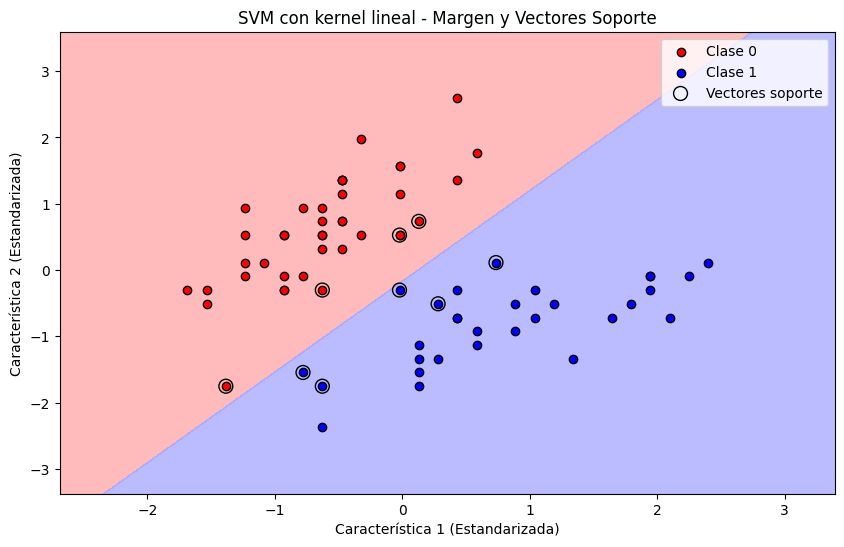

In [9]:
# Visualizar las fronteras de decisión
plot_decision_boundaries(X_train, y_train, svm)

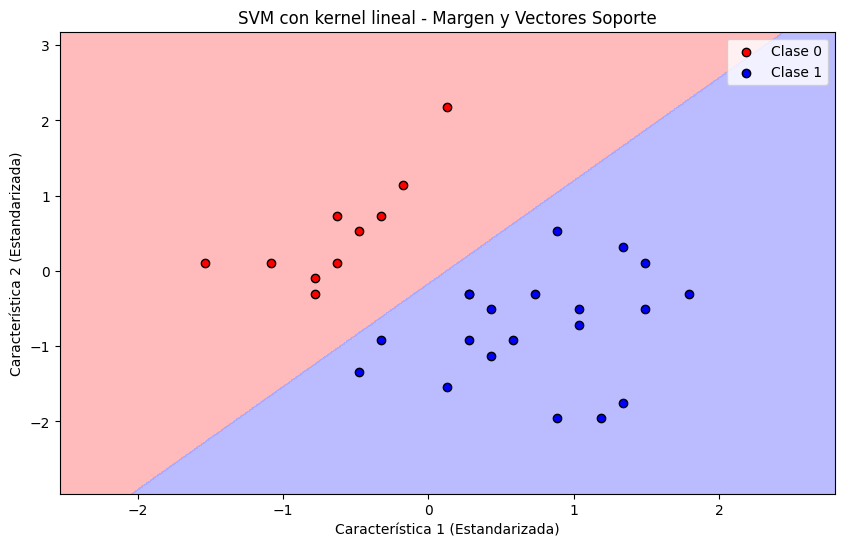

In [10]:
plot_decision_boundaries(X_test, y_test, svm, plot_sv=False)

In [11]:
y_pred = svm.predict(X_test)

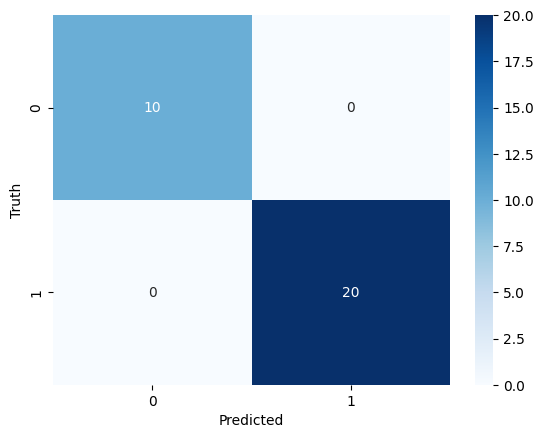

In [12]:
# confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()


In [13]:
#reporte de clasificación
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



#### Clasificación Multiclase

In [14]:
data = datasets.load_iris()

In [15]:
# Explanatory variables.
X = data['data']
columns = list(data['feature_names'])
print(columns)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [16]:
# Response variable.
Y = data['target']
labels = list(data['target_names'])
print(labels)

[np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [17]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1234)

##### SVM hyperparameter optimization (RBF kernel):

C     : Penalty parameter. <br>
gamma : kernel parameter ($\gamma$).

In [18]:
C_grid = 0.02*np.arange(1,20)
gamma_grid = 0.02*np.arange(1,50)
parameters = {'C': C_grid, 'gamma' : gamma_grid}
gridCV = GridSearchCV(SVC(kernel='rbf'), parameters, cv=10, n_jobs=-1)              # "n_jobs = -1" means "use all the CPU cores".
gridCV.fit(X_train, Y_train)
best_C = gridCV.best_params_['C']
best_gamma = gridCV.best_params_['gamma']

print("SVM best C : " + str(best_C))
print("SVM best gamma : " + str(best_gamma))

SVM best C : 0.2
SVM best gamma : 0.78


In [19]:
SVM_best = SVC(kernel='rbf', C=best_C,gamma=best_gamma)
SVM_best.fit(X_train, Y_train);
Y_pred = SVM_best.predict(X_test)

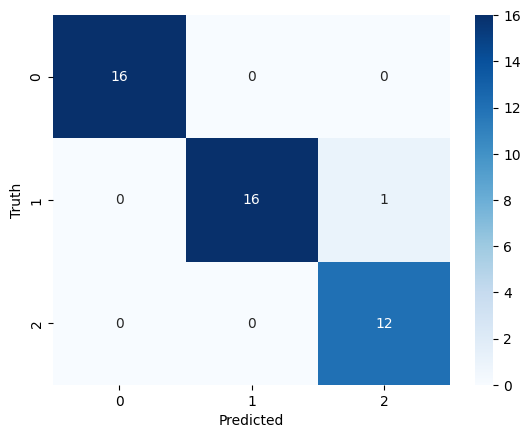

In [20]:
# confusion matrix
cm = confusion_matrix(Y_test, Y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

In [21]:
# Classification report
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      0.94      0.97        17
           2       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



### SVM hyperparameter optimization (Polynomial kernel):

In [22]:
C_grid = 0.0001*np.arange(1,30)
gamma_grid = 0.01*np.arange(1,30)
parameters = {'C': C_grid, 'gamma' : gamma_grid}
gridCV = GridSearchCV(SVC(kernel='poly'), parameters, cv=10, n_jobs=-1)              # "n_jobs = -1" means "use all the CPU cores".
gridCV.fit(X_train, Y_train)
best_C = gridCV.best_params_['C']
best_gamma = gridCV.best_params_['gamma']

print("SVM best C : " + str(best_C))
print("SVM best gamma : " + str(best_gamma))

SVM best C : 0.0007
SVM best gamma : 0.27


In [23]:
SVM_best = SVC(kernel='poly', C=best_C,gamma=best_gamma)
SVM_best.fit(X_train, Y_train);
Y_pred = SVM_best.predict(X_test)

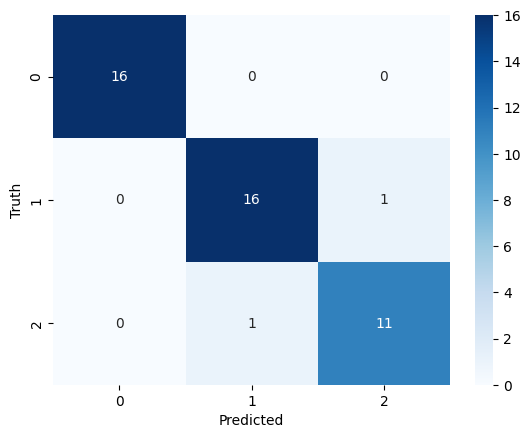

In [24]:
# confusion matrix
cm = confusion_matrix(Y_test, Y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

In [25]:
# Classification report
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.94      0.94      0.94        17
           2       0.92      0.92      0.92        12

    accuracy                           0.96        45
   macro avg       0.95      0.95      0.95        45
weighted avg       0.96      0.96      0.96        45

